# Step 6 — Clinical and survival analysis

## tl;dr

This notebook rebuilds patient-level clinical and overall-survival evidence from the canonical subtype master table. It uses study-stratified Cox models, explicitly diagnoses non-proportional hazards, and reports time-varying subtype effects. Observed pathology variables remain separate from predictions.

## Context & Methods

The principal-state survival population contains 331 tumors and 153 deaths from four studies. The core model adjusts for age, sex, and stage group with study-specific baseline hazards. Because subtype and age violate proportional hazards, constant Cox estimates are average-association summaries and a log-time interaction model supplies the interpretable time course.

### Key assumptions

- Survival is retrospective and available-case.
- Each tumor contributes one analytical record.
- Six-state analyses are exploratory.
- Clinical association tests are descriptive and may reflect study composition.

In [ ]:
r_home <- Sys.getenv("ICCA_R_HOME", unset = "")
if (!nzchar(r_home)) r_home <- Sys.getenv("R_HOME", unset = "")
if (!nzchar(r_home)) {
  r_command <- Sys.which("R")
  if (!nzchar(r_command)) stop("Set ICCA_R_HOME or R_HOME, or make R available on PATH")
  r_home <- system2(r_command, "RHOME", stdout = TRUE, stderr = TRUE)
  if (length(r_home) != 1L || !is.null(attr(r_home, "status"))) stop("R RHOME failed")
}
r_home <- normalizePath(r_home, winslash = "/", mustWork = TRUE)
r_candidates <- c(file.path(r_home, "bin", "exec", "R"),
                  file.path(r_home, "bin", c("R", "R.exe")))
r_exec <- r_candidates[file.exists(r_candidates)][1]
if (is.na(r_exec)) stop("No R executable found under ", r_home)
r45_env <- paste0("R_HOME=", shQuote(r_home))
run_r45 <- function(script) {
  out <- system2(r_exec, c("--vanilla", "--slave", "-f", shQuote(script)),
                 stdout = TRUE, stderr = TRUE, env = r45_env)
  cat(paste(out, collapse = "\n"), "\n")
  status <- attr(out, "status")
  if (!is.null(status) && status != 0L) stop("R script failed: ", script)
  invisible(out)
}
stopifnot(normalizePath(getwd(), winslash = '/', mustWork = TRUE) == normalizePath('.', winslash = '/', mustWork = TRUE))
core_refresh <- identical(Sys.getenv("SCLUCID_STEP6_REFRESH", "0"), "1")
targeted_refresh <- identical(Sys.getenv("SCLUCID_STEP6_TARGETED_REFRESH", "0"), "1")
if (core_refresh) {
  run_r45("6-ClinicalSurvival/scripts/run_step6_clinical_survival.R")
  run_r45("6-ClinicalSurvival/scripts/finalize_step6_release.R")
}
if (targeted_refresh) run_r45("6-ClinicalSurvival/scripts/run_step6_targeted_upgrades.R")

suppressPackageStartupMessages(library(data.table))
table_dir <- "6-ClinicalSurvival/publication/tables"
gate <- fread(file.path(table_dir, "step6_clinical_survival_release_gate_status.csv"))
targeted_gate <- fread(file.path(table_dir, "step6_targeted_upgrade_release_gate_status.csv"))
stopifnot(all(gate$Pass), all(targeted_gate$Pass))
list(core_release_gate = gate, targeted_upgrade_gate = targeted_gate)

## Data

Analysis populations, missingness, formulas, references, and event counts are saved before model interpretation.

In [2]:
contract <- fread(file.path(table_dir, 'step6_survival_model_contract.csv'))
population <- fread(file.path(table_dir, 'step6_survival_population_by_study_and_state.csv'))
missingness <- fread(file.path(table_dir, 'step6_clinical_variable_missingness.csv'))
contract
population[ValidOSN > 0]
missingness[Study == 'All studies']

Analysis,Scope,N,Events,Formula,Reference
<chr>,<chr>,<int>,<int>,<chr>,<chr>
Main states,Average-association summary,331,153,"Surv(OS months, event) ~ subtype + age + sex + stage group + strata(Study)",C1; Female; stage I/II
Main states,Non-PH adjudication,331,153,"Surv(OS months, event) ~ subtype indicators + age + sex + stage group + log(time) interactions for subtype and age + strata(Study)",C1; Female; stage I/II
Main states,Sensitivity,239,101,"Surv(OS months, event) ~ subtype + age + sex + stage group + tumor size + HBV + vascular invasion + strata(Study)",C1; Female; stage I/II
All six states,Exploratory,388,180,"Surv(OS months, event) ~ six-state subtype + age + sex + stage group + strata(Study)",C1; Female; stage I/II


Study,FinalSubtype,SubtypeClass,TotalN,ValidOSN,Events
<chr>,<chr>,<chr>,<int>,<int>,<int>
2022Dong,C2_C3,Intermediate,4,4,3
2022Dong,C2,Main,108,107,29
2022Dong,C1,Main,48,46,18
2022Dong,C3,Main,67,61,39
2022Dong,C1_C2,Intermediate,14,14,4
2022Dong,C1_C3,Intermediate,14,12,6
2023Deng,C2,Main,32,32,14
2023Deng,C1,Main,9,9,6
2023Deng,C3,Main,23,22,17


Study,Variable,EligibleN,AvailableN,MissingN,MissingFraction
<chr>,<chr>,<int>,<int>,<int>,<dbl>
All studies,Overall survival time,497,331,166,0.3340040
All studies,Vital status,497,331,166,0.3340040
All studies,Age,497,341,156,0.3138833
All studies,Sex,497,433,64,0.1287726
All studies,Stage group,497,341,156,0.3138833
All studies,Tumor size,497,312,185,0.3722334
All studies,HBV,497,308,189,0.3802817
All studies,Vascular invasion,497,248,249,0.5010060
All studies,Observed duct type,497,93,404,0.8128773


## Results

The results below separate average Cox associations, proportional-hazards diagnostics, and time-varying effects.

In [3]:
pairwise <- fread(file.path(table_dir, 'step6_cox_main_states_pairwise.csv'))
ph <- fread(file.path(table_dir, 'step6_cox_proportional_hazards_diagnostics.csv'))
time_varying <- fread(file.path(table_dir, 'step6_cox_time_varying_subtype_effects.csv'))
pairwise
ph[Model == 'Core study-stratified Cox']
time_varying[TimeMonths %in% c(6, 12, 24)]

Target,Reference,HR,Lower95,Upper95,PValue,N,Events,Formula,FDR
<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<int>,<chr>,<dbl>
C2,C1,0.7256095,0.4593765,1.146139,1.690803e-01,331,153,"Surv(OS months, event) ~ subtype + age + sex + stage group + strata(Study)",1.690803e-01
C3,C1,2.3540939,1.5170638,3.652950,1.339372e-04,331,153,"Surv(OS months, event) ~ subtype + age + sex + stage group + strata(Study)",2.009058e-04
C3,C2,3.2442988,2.2201368,4.740913,1.194906e-09,331,153,"Surv(OS months, event) ~ subtype + age + sex + stage group + strata(Study)",3.584717e-09


Model,Scope,Term,ChiSquare,DF,PValue
<chr>,<chr>,<chr>,<dbl>,<int>,<dbl>
Core study-stratified Cox,Headline,FinalSubtype,1.165535e+01,2,0.002944919
Core study-stratified Cox,Headline,age_years,7.890284e+00,1,0.004970105
Core study-stratified Cox,Headline,sex_clean,3.341851e-04,1,0.985414900
Core study-stratified Cox,Headline,stage_group,1.663556e+00,1,0.197123863
Core study-stratified Cox,Headline,GLOBAL,1.869455e+01,5,0.002190835


Contrast,TimeMonths,HR,Lower95,Upper95,PValue,N,Events,FDR
<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<int>,<dbl>
C2 vs C1,6,0.5214151,0.2003390,1.357068,1.820836e-01,331,153,3.065058e-01
C2 vs C1,12,0.6123474,0.3468991,1.080918,9.071755e-02,331,153,2.041145e-01
C2 vs C1,24,0.7191380,0.4405259,1.173959,1.873091e-01,331,153,3.065058e-01
C3 vs C1,6,3.9236157,1.7757504,8.669439,7.258081e-04,331,153,2.612909e-03
C3 vs C1,12,2.4168535,1.4777415,3.952776,4.383269e-04,331,153,1.972471e-03
C3 vs C1,24,1.4887239,0.8522418,2.600552,1.620531e-01,331,153,3.065058e-01
C3 vs C2,6,7.5249374,3.5029455,16.164877,2.298083e-07,331,153,2.068274e-06
C3 vs C2,12,3.9468662,2.4954608,6.242435,4.367467e-09,331,153,7.861440e-08
C3 vs C2,24,2.0701505,1.2628905,3.393424,3.906134e-03,331,153,1.004434e-02


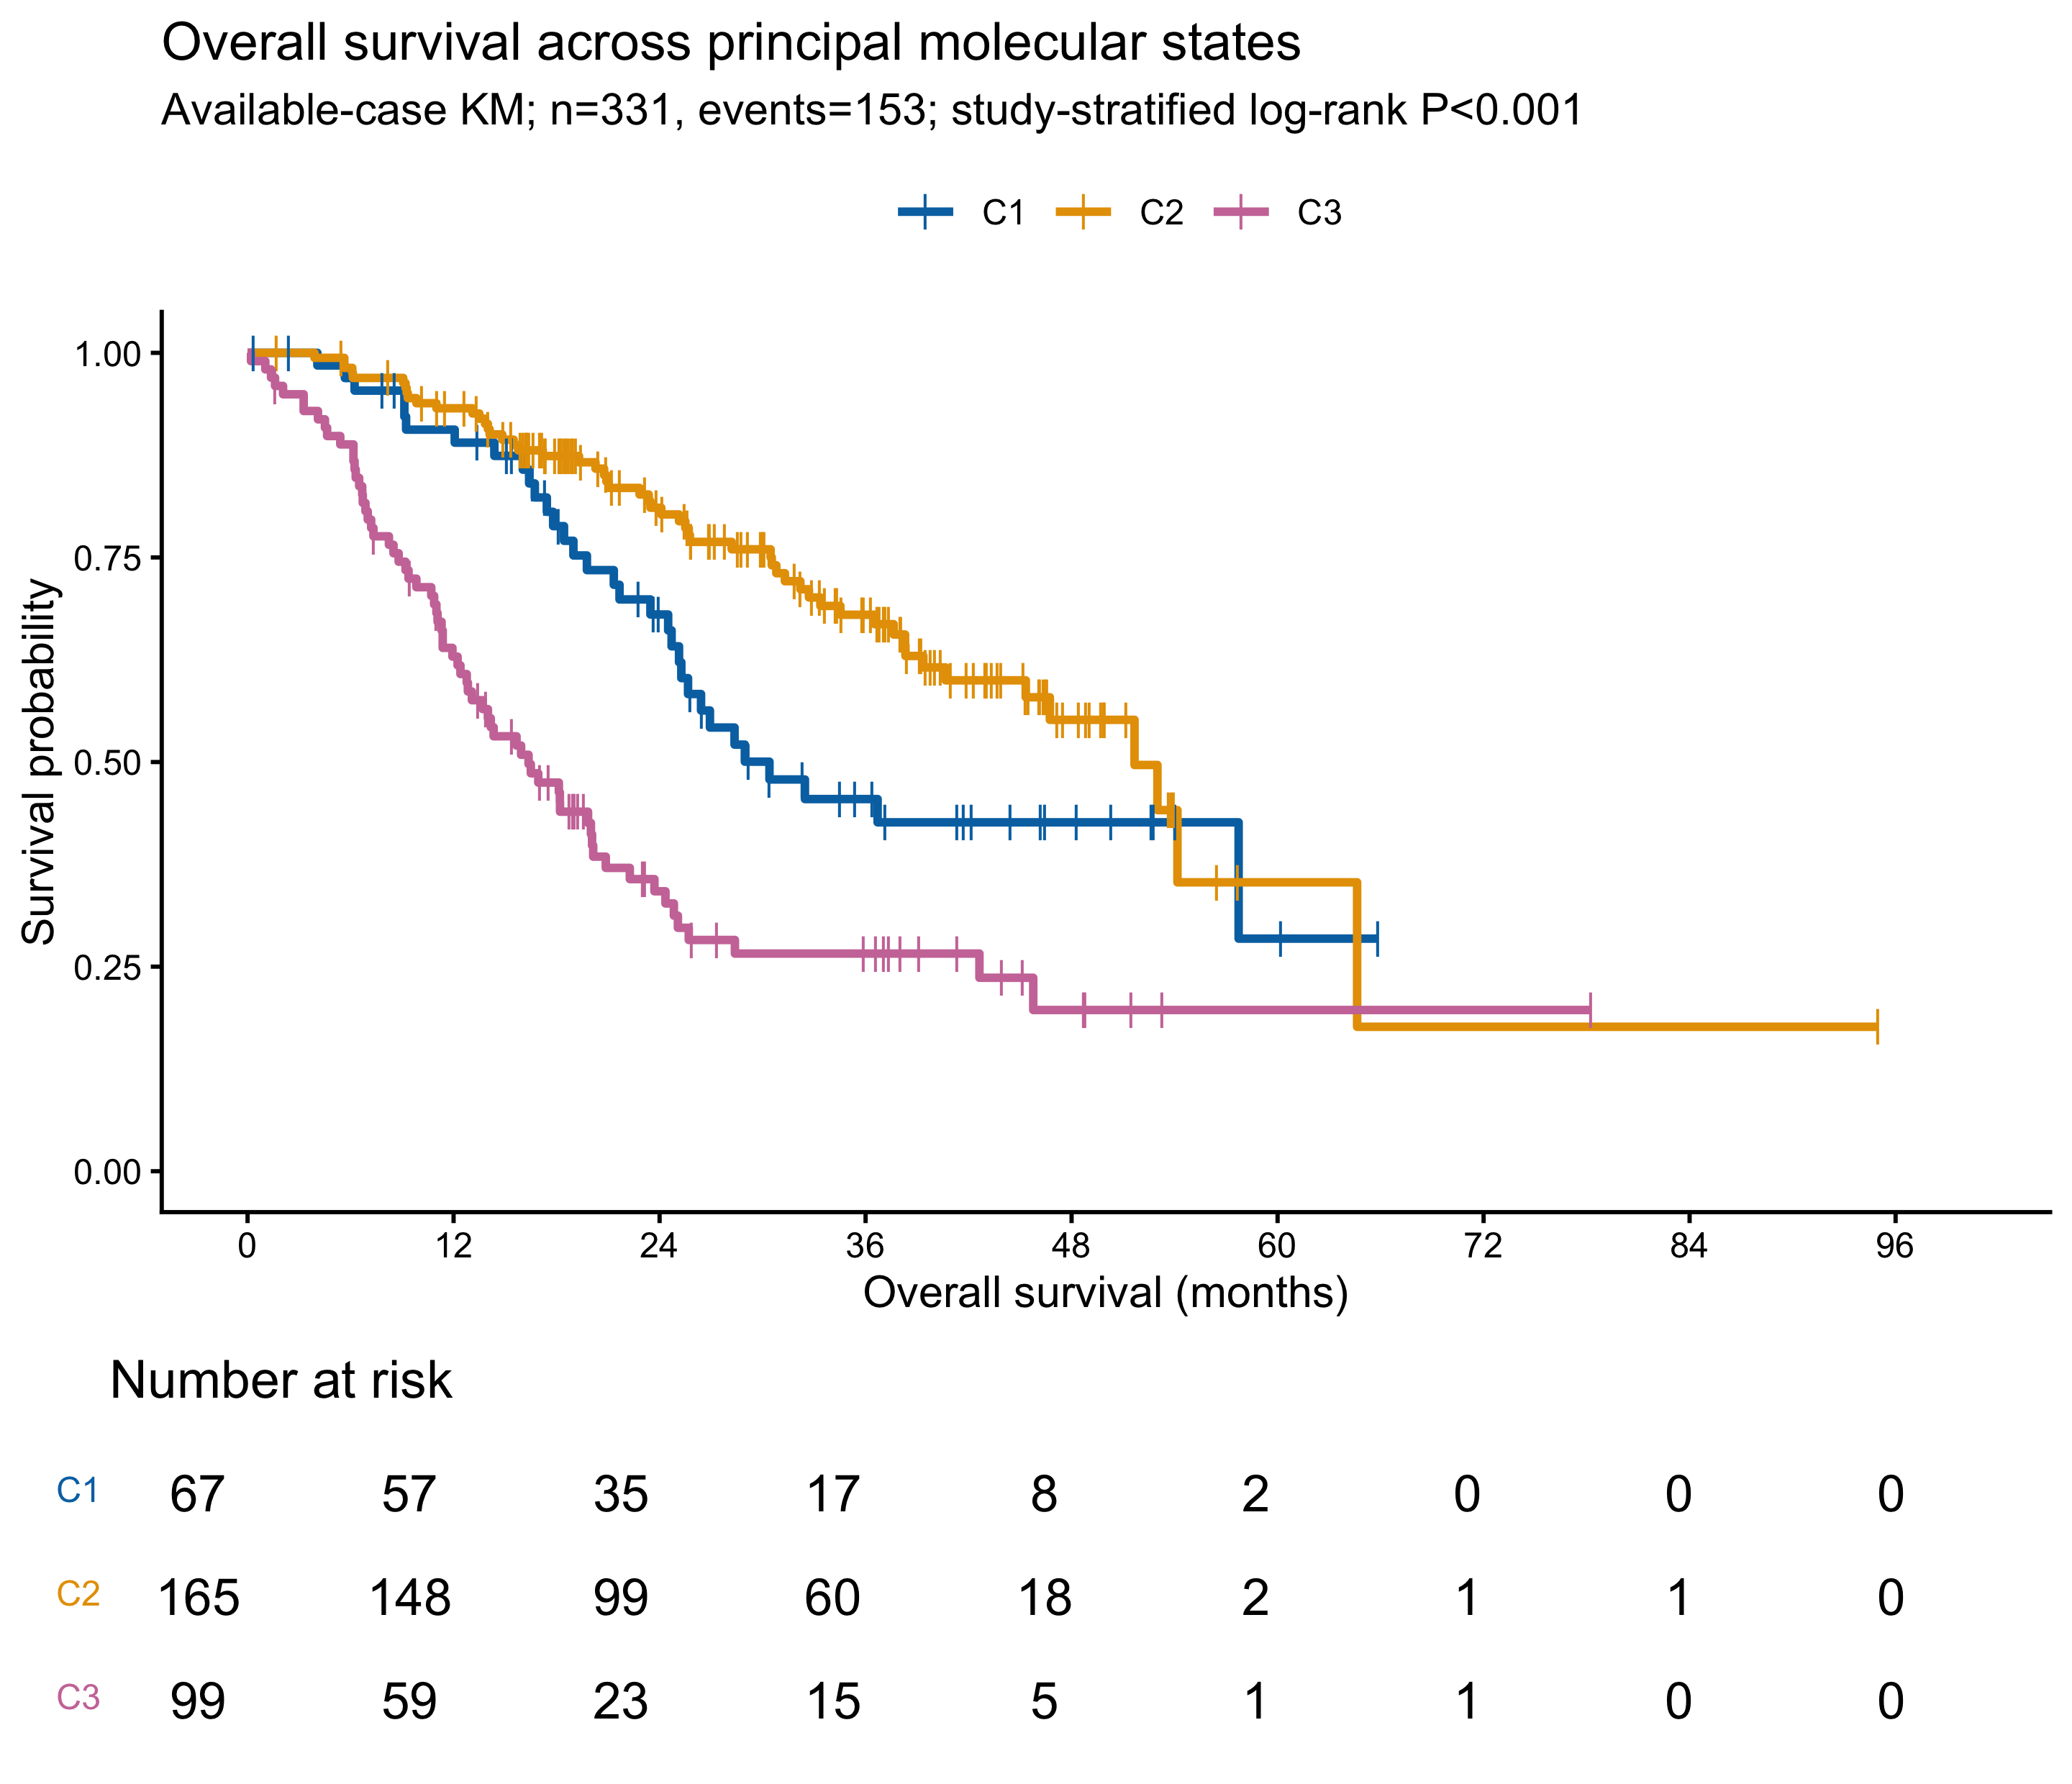

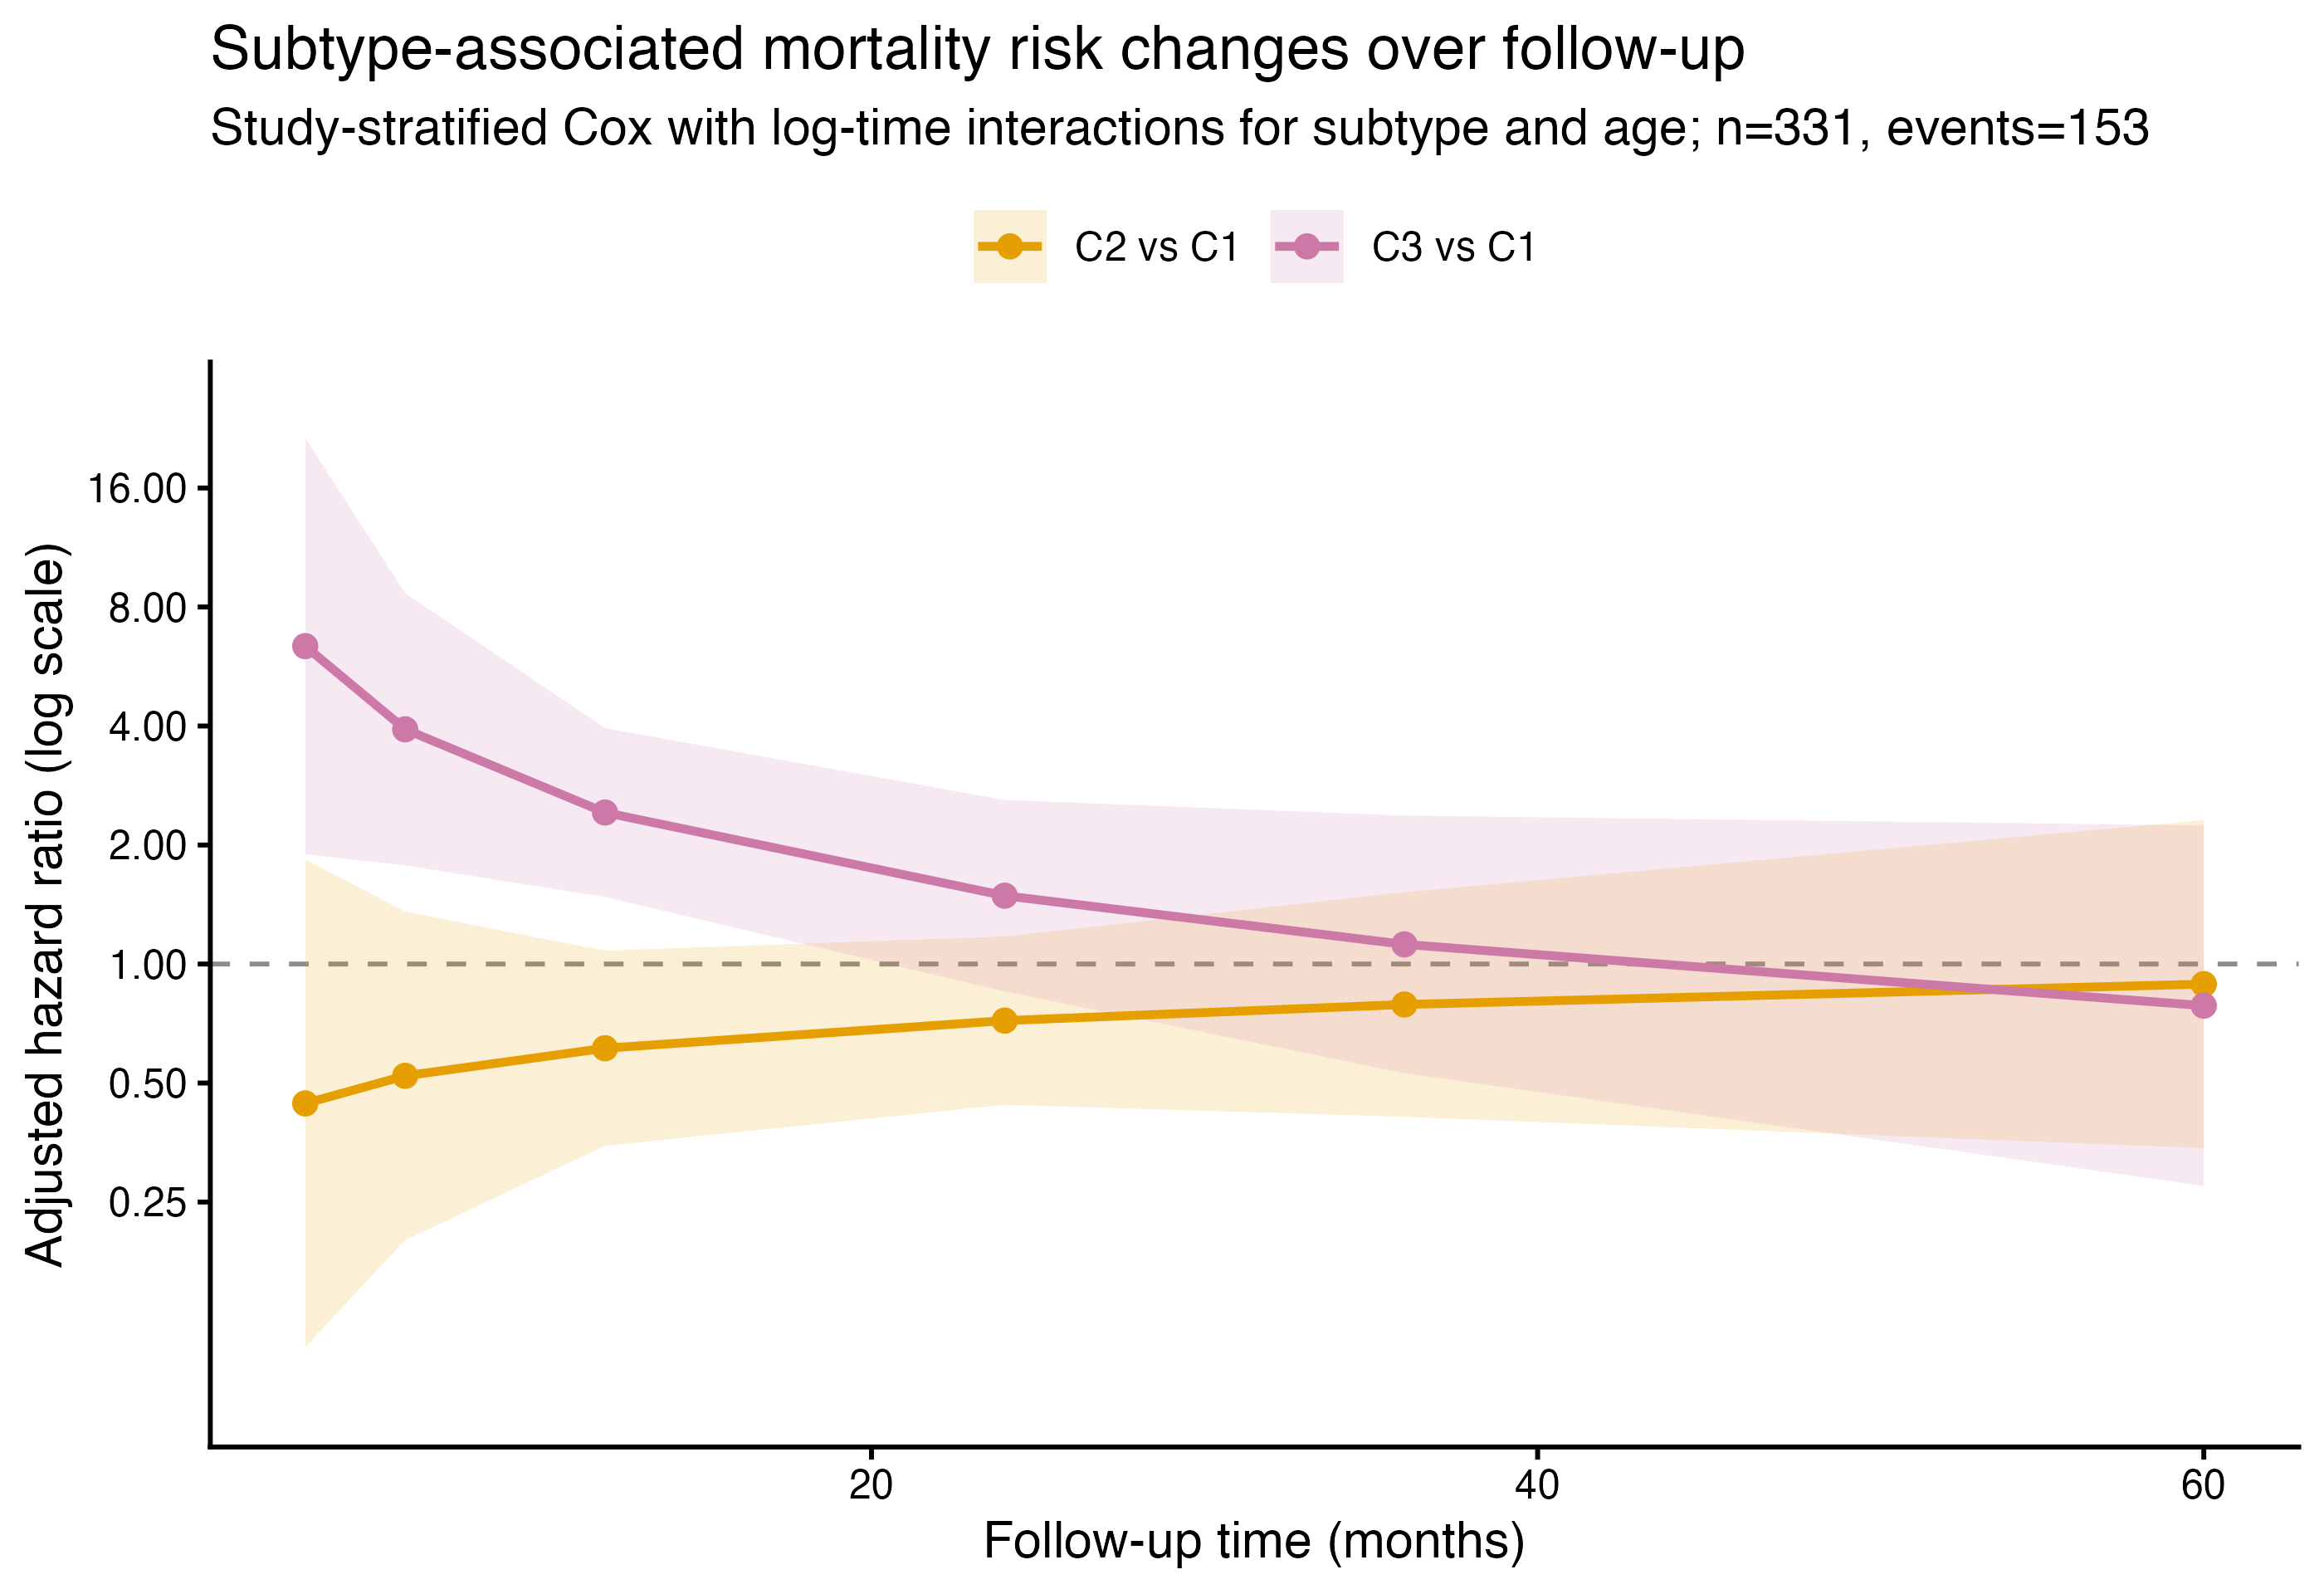

In [4]:
if (requireNamespace('IRdisplay', quietly = TRUE)) {
  IRdisplay::display_png(file = '6-ClinicalSurvival/publication/figures/step6_km_main_states.png')
  IRdisplay::display_png(file = '6-ClinicalSurvival/publication/figures/step6_cox_time_varying_subtype_effects.png')
}

## Targeted clinical and prognostic upgrades

Clinical phenotype associations are estimated with Study-adjusted HC3 models for tumor size, advanced stage, vascular invasion and observed large-duct morphology. Study-specific estimates and random-effects summaries are sensitivity analyses; the one-stage adjusted model is primary when studies or events are sparse.

Incremental prognostic value compares age/sex/stage with age/sex/stage plus subtype in the same 331 patients using repeated 5x5 out-of-fold Cox predictions. C-index, 6/12/24-month IPCW AUC and Brier score, 3–36-month integrated Brier score, calibration, likelihood-ratio tests and 500 paired Study-stratified bootstrap intervals are exported. Because C3 violates proportional hazards, an early 24-month analysis is reported alongside full follow-up. Six-month calibration is sparse and is not a headline claim.

Endpoint,PositiveLevel,Target,Reference,N,MissingN,Studies,EffectScale,Estimate,Lower95,Upper95,PValue,FDR,Model
<chr>,<chr>,<chr>,<chr>,<int>,<int>,<int>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
Tumor size,larger size in cm,C2,C1,312,185,3,Mean difference (cm),1.0772975,0.2506659,1.9039290,1.112132e-02,2.669116e-02,Outcome ~ subtype + Study; HC3 robust covariance
Tumor size,larger size in cm,C3,C1,312,185,3,Mean difference (cm),1.1762347,0.2917648,2.0607046,9.592061e-03,2.669116e-02,Outcome ~ subtype + Study; HC3 robust covariance
Tumor size,larger size in cm,C3,C2,312,185,3,Mean difference (cm),0.0989372,-0.5707687,0.7686431,7.723519e-01,8.425657e-01,Outcome ~ subtype + Study; HC3 robust covariance
Advanced stage,stage III/IV,C2,C1,341,156,4,Odds ratio,0.6401945,0.3341201,1.2266516,1.788677e-01,2.384902e-01,Outcome ~ subtype + Study; HC3 robust covariance
Advanced stage,stage III/IV,C3,C1,341,156,4,Odds ratio,2.3305649,1.1710510,4.6381693,1.596567e-02,3.193134e-02,Outcome ~ subtype + Study; HC3 robust covariance
Advanced stage,stage III/IV,C3,C2,341,156,4,Odds ratio,3.6404015,2.0929589,6.3319556,4.755123e-06,5.706148e-05,Outcome ~ subtype + Study; HC3 robust covariance
Vascular invasion,vascular invasion present,C2,C1,248,249,2,Odds ratio,0.6736713,0.3412928,1.3297469,2.548850e-01,3.058620e-01,Outcome ~ subtype + Study; HC3 robust covariance
Vascular invasion,vascular invasion present,C3,C1,248,249,2,Odds ratio,1.8066838,0.8737409,3.7357832,1.105229e-01,1.657843e-01,Outcome ~ subtype + Study; HC3 robust covariance
Vascular invasion,vascular invasion present,C3,C2,248,249,2,Odds ratio,2.6818476,1.4703408,4.8915913,1.294658e-03,5.178630e-03,Outcome ~ subtype + Study; HC3 robust covariance


Endpoint,Target,Reference,Studies,EffectScale,Estimate,Lower95,Upper95,PValue,Tau2,I2Percent,QPValue,MetaMethod,FDR
<chr>,<chr>,<chr>,<int>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>
Tumor size,C2,C1,3,Random-effects mean difference (cm),1.3404291,0.15542945,2.5254287,2.661751e-02,0.3877649,31.70288,0.2312651,DerSimonian-Laird random effects,0.0638820196
Tumor size,C3,C1,3,Random-effects mean difference (cm),1.3236330,0.51399342,2.1332727,1.353957e-03,0.0000000,0.00000,0.8383595,DerSimonian-Laird random effects,0.0054158264
Tumor size,C3,C2,3,Random-effects mean difference (cm),0.1856971,-0.46128683,0.8326811,5.737355e-01,0.0000000,0.00000,0.3684438,DerSimonian-Laird random effects,0.5872514043
Advanced stage,C2,C1,4,Random-effects odds ratio,0.4911258,0.13074067,1.8449082,2.923276e-01,0.7777670,42.23124,0.1581901,DerSimonian-Laird random effects,0.4384914197
Advanced stage,C3,C1,4,Random-effects odds ratio,1.9646192,0.80059377,4.8210827,1.403691e-01,0.2059775,20.80138,0.2852915,DerSimonian-Laird random effects,0.2406327926
Advanced stage,C3,C2,4,Random-effects odds ratio,3.6828691,2.09349949,6.4788764,6.076692e-06,0.0000000,0.00000,0.6445230,DerSimonian-Laird random effects,0.0000729203
Vascular invasion,C2,C1,2,Random-effects odds ratio,0.6196581,0.23682474,1.6213516,3.294417e-01,0.1561860,16.31289,0.2743379,DerSimonian-Laird random effects,0.4392555558
Vascular invasion,C3,C1,2,Random-effects odds ratio,1.6004096,0.57334275,4.4673295,3.692459e-01,0.1937659,22.33249,0.2565019,DerSimonian-Laird random effects,0.4430950503
Vascular invasion,C3,C2,2,Random-effects odds ratio,2.7458422,1.50958382,4.9945218,9.354591e-04,0.0000000,0.00000,0.9497284,DerSimonian-Laird random effects,0.0054158264


Comparison,Metric,Estimate,Lower95,Upper95,N,Events,Interpretation
<chr>,<chr>,<dbl>,<dbl>,<dbl>,<int>,<int>,<chr>
Delta: clinical + subtype minus clinical,CIndex,0.0745637395,0.034969978,0.116526393,331,153,Positive delta favors adding subtype
Delta: clinical + subtype minus clinical,AUC6,0.0318368996,-0.058250500,0.122979833,331,153,Positive delta favors adding subtype
Delta: clinical + subtype minus clinical,AUC12,0.1056123497,0.046875346,0.177185084,331,153,Positive delta favors adding subtype
Delta: clinical + subtype minus clinical,AUC24,0.1119696046,0.061401372,0.173815524,331,153,Positive delta favors adding subtype
Delta: clinical + subtype minus clinical,Brier6,-0.0005063093,-0.002724887,0.001567061,331,153,Negative delta favors adding subtype
Delta: clinical + subtype minus clinical,Brier12,-0.0110186507,-0.019697278,-0.003356325,331,153,Negative delta favors adding subtype
Delta: clinical + subtype minus clinical,Brier24,-0.0287813898,-0.045925300,-0.013026657,331,153,Negative delta favors adding subtype
Delta: clinical + subtype minus clinical,IBS3to36,-0.0173417331,-0.027421504,-0.007768107,331,153,Negative delta favors adding subtype


Model,HorizonMonths,CalibrationIntercept,CalibrationSlope,N,Method
<chr>,<int>,<dbl>,<dbl>,<int>,<chr>
Clinical,6,-3.65286503,-0.2082661,331,IPCW-weighted logistic calibration of repeated-CV OOF risk
Clinical,12,-0.21512833,0.8654590,331,IPCW-weighted logistic calibration of repeated-CV OOF risk
Clinical,24,-0.12809462,0.7852485,331,IPCW-weighted logistic calibration of repeated-CV OOF risk
ClinicalPlusSubtype,6,-2.63526273,0.1011455,331,IPCW-weighted logistic calibration of repeated-CV OOF risk
ClinicalPlusSubtype,12,0.03069561,1.0354571,331,IPCW-weighted logistic calibration of repeated-CV OOF risk
ClinicalPlusSubtype,24,-0.05323622,0.9539938,331,IPCW-weighted logistic calibration of repeated-CV OOF risk


Scope,N,Events,ClinicalLogLik,ClinicalPlusSubtypeLogLik,LRChiSquare,DF,PValue,Interpretation
<chr>,<int>,<int>,<dbl>,<dbl>,<dbl>,<int>,<dbl>,<chr>
Full follow-up,331,153,-609.7498,-590.8961,37.70747,2,6.485269e-09,Average-association benchmark; PH violation requires time-specific interpretation
Early 24-month restricted follow-up,331,107,-463.6124,-440.8419,45.54102,2,1.290905e-10,Addresses early C3 risk; not a lifetime effect


Scope,Target,Reference,Studies,HR,Lower95,Upper95,PValue,Tau2,I2Percent,QPValue,MetaMethod,Interpretation,FDR
<chr>,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<dbl>
Full follow-up,C3,C1,3,2.1925188,1.3302876,3.613609,2.073349e-03,0.0197069,8.481922,0.3353165,DerSimonian-Laird,Random-effects sensitivity; one-stage Study-stratified Cox remains primary,3.110023e-03
Full follow-up,C3,C2,4,3.5245223,2.3564615,5.271572,8.616478e-10,0.0000000,0.000000,0.9314508,DerSimonian-Laird,Random-effects sensitivity; one-stage Study-stratified Cox remains primary,4.439960e-09
Full follow-up,C2,C1,3,0.7611279,0.4641605,1.248094,2.793751e-01,0.0000000,0.000000,0.8567634,DerSimonian-Laird,Random-effects sensitivity; one-stage Study-stratified Cox remains primary,2.793751e-01
Early 24-month restricted follow-up,C3,C1,3,3.0104569,1.7127864,5.291291,1.280568e-04,0.0000000,0.000000,0.4695635,DerSimonian-Laird,Random-effects sensitivity; one-stage Study-stratified Cox remains primary,2.561136e-04
Early 24-month restricted follow-up,C3,C2,3,4.7101139,2.8501411,7.783886,1.479987e-09,0.0000000,0.000000,0.7585773,DerSimonian-Laird,Random-effects sensitivity; one-stage Study-stratified Cox remains primary,4.439960e-09
Early 24-month restricted follow-up,C2,C1,3,0.6603638,0.3407234,1.279867,2.190287e-01,0.0000000,0.000000,0.5668080,DerSimonian-Laird,Random-effects sensitivity; one-stage Study-stratified Cox remains primary,2.628345e-01


Scope,Target,Reference,HeldOutStudy,StudiesRemaining,HR,Lower95,Upper95,PValue
<chr>,<chr>,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>
Full follow-up,C3,C1,2019Ahn,2,2.461059,1.4655590,4.132764,0.0006608878
Full follow-up,C3,C1,2022Dong,2,1.437669,0.6679407,3.094427,0.3533126893
Full follow-up,C3,C1,2023Deng,2,2.226973,1.0003944,4.957455,0.0498830039
Early 24-month restricted follow-up,C3,C1,2019Ahn,2,3.021662,1.4901416,6.127228,0.0021702888
Early 24-month restricted follow-up,C3,C1,2022Dong,2,1.825445,0.6862921,4.855441,0.2279065203
Early 24-month restricted follow-up,C3,C1,2023Deng,2,3.554910,1.8616033,6.788442,0.0001215995


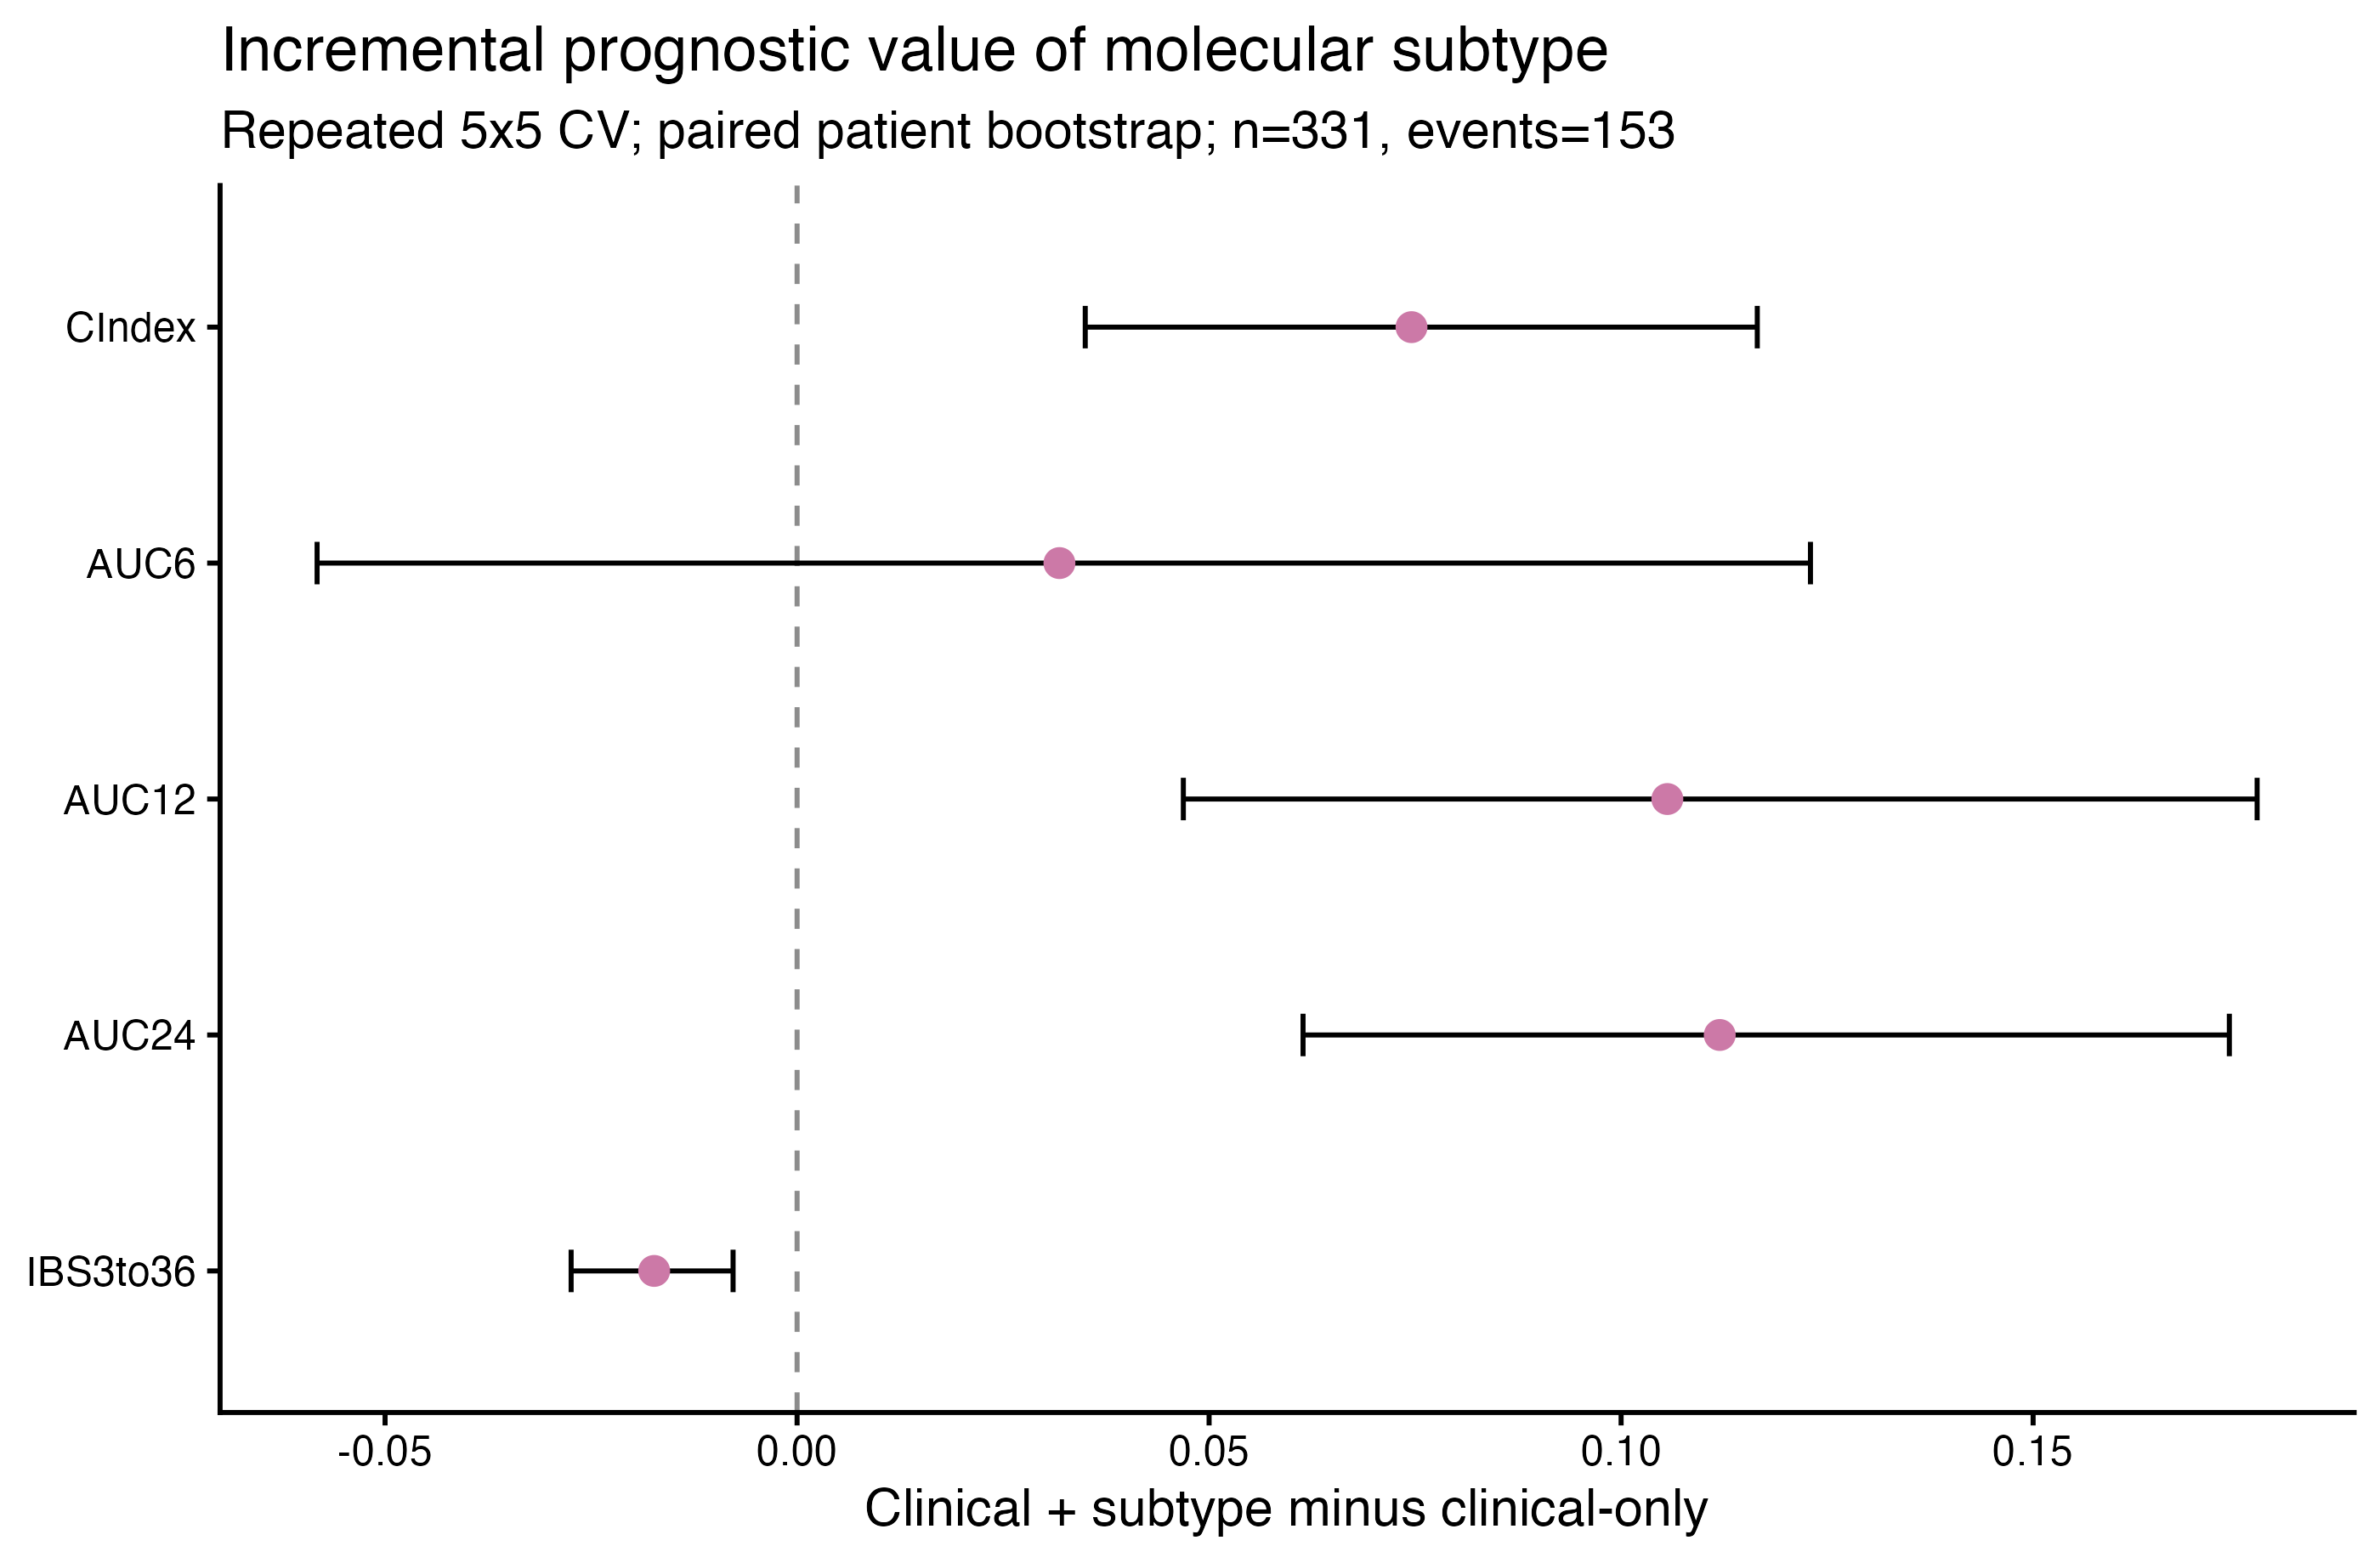

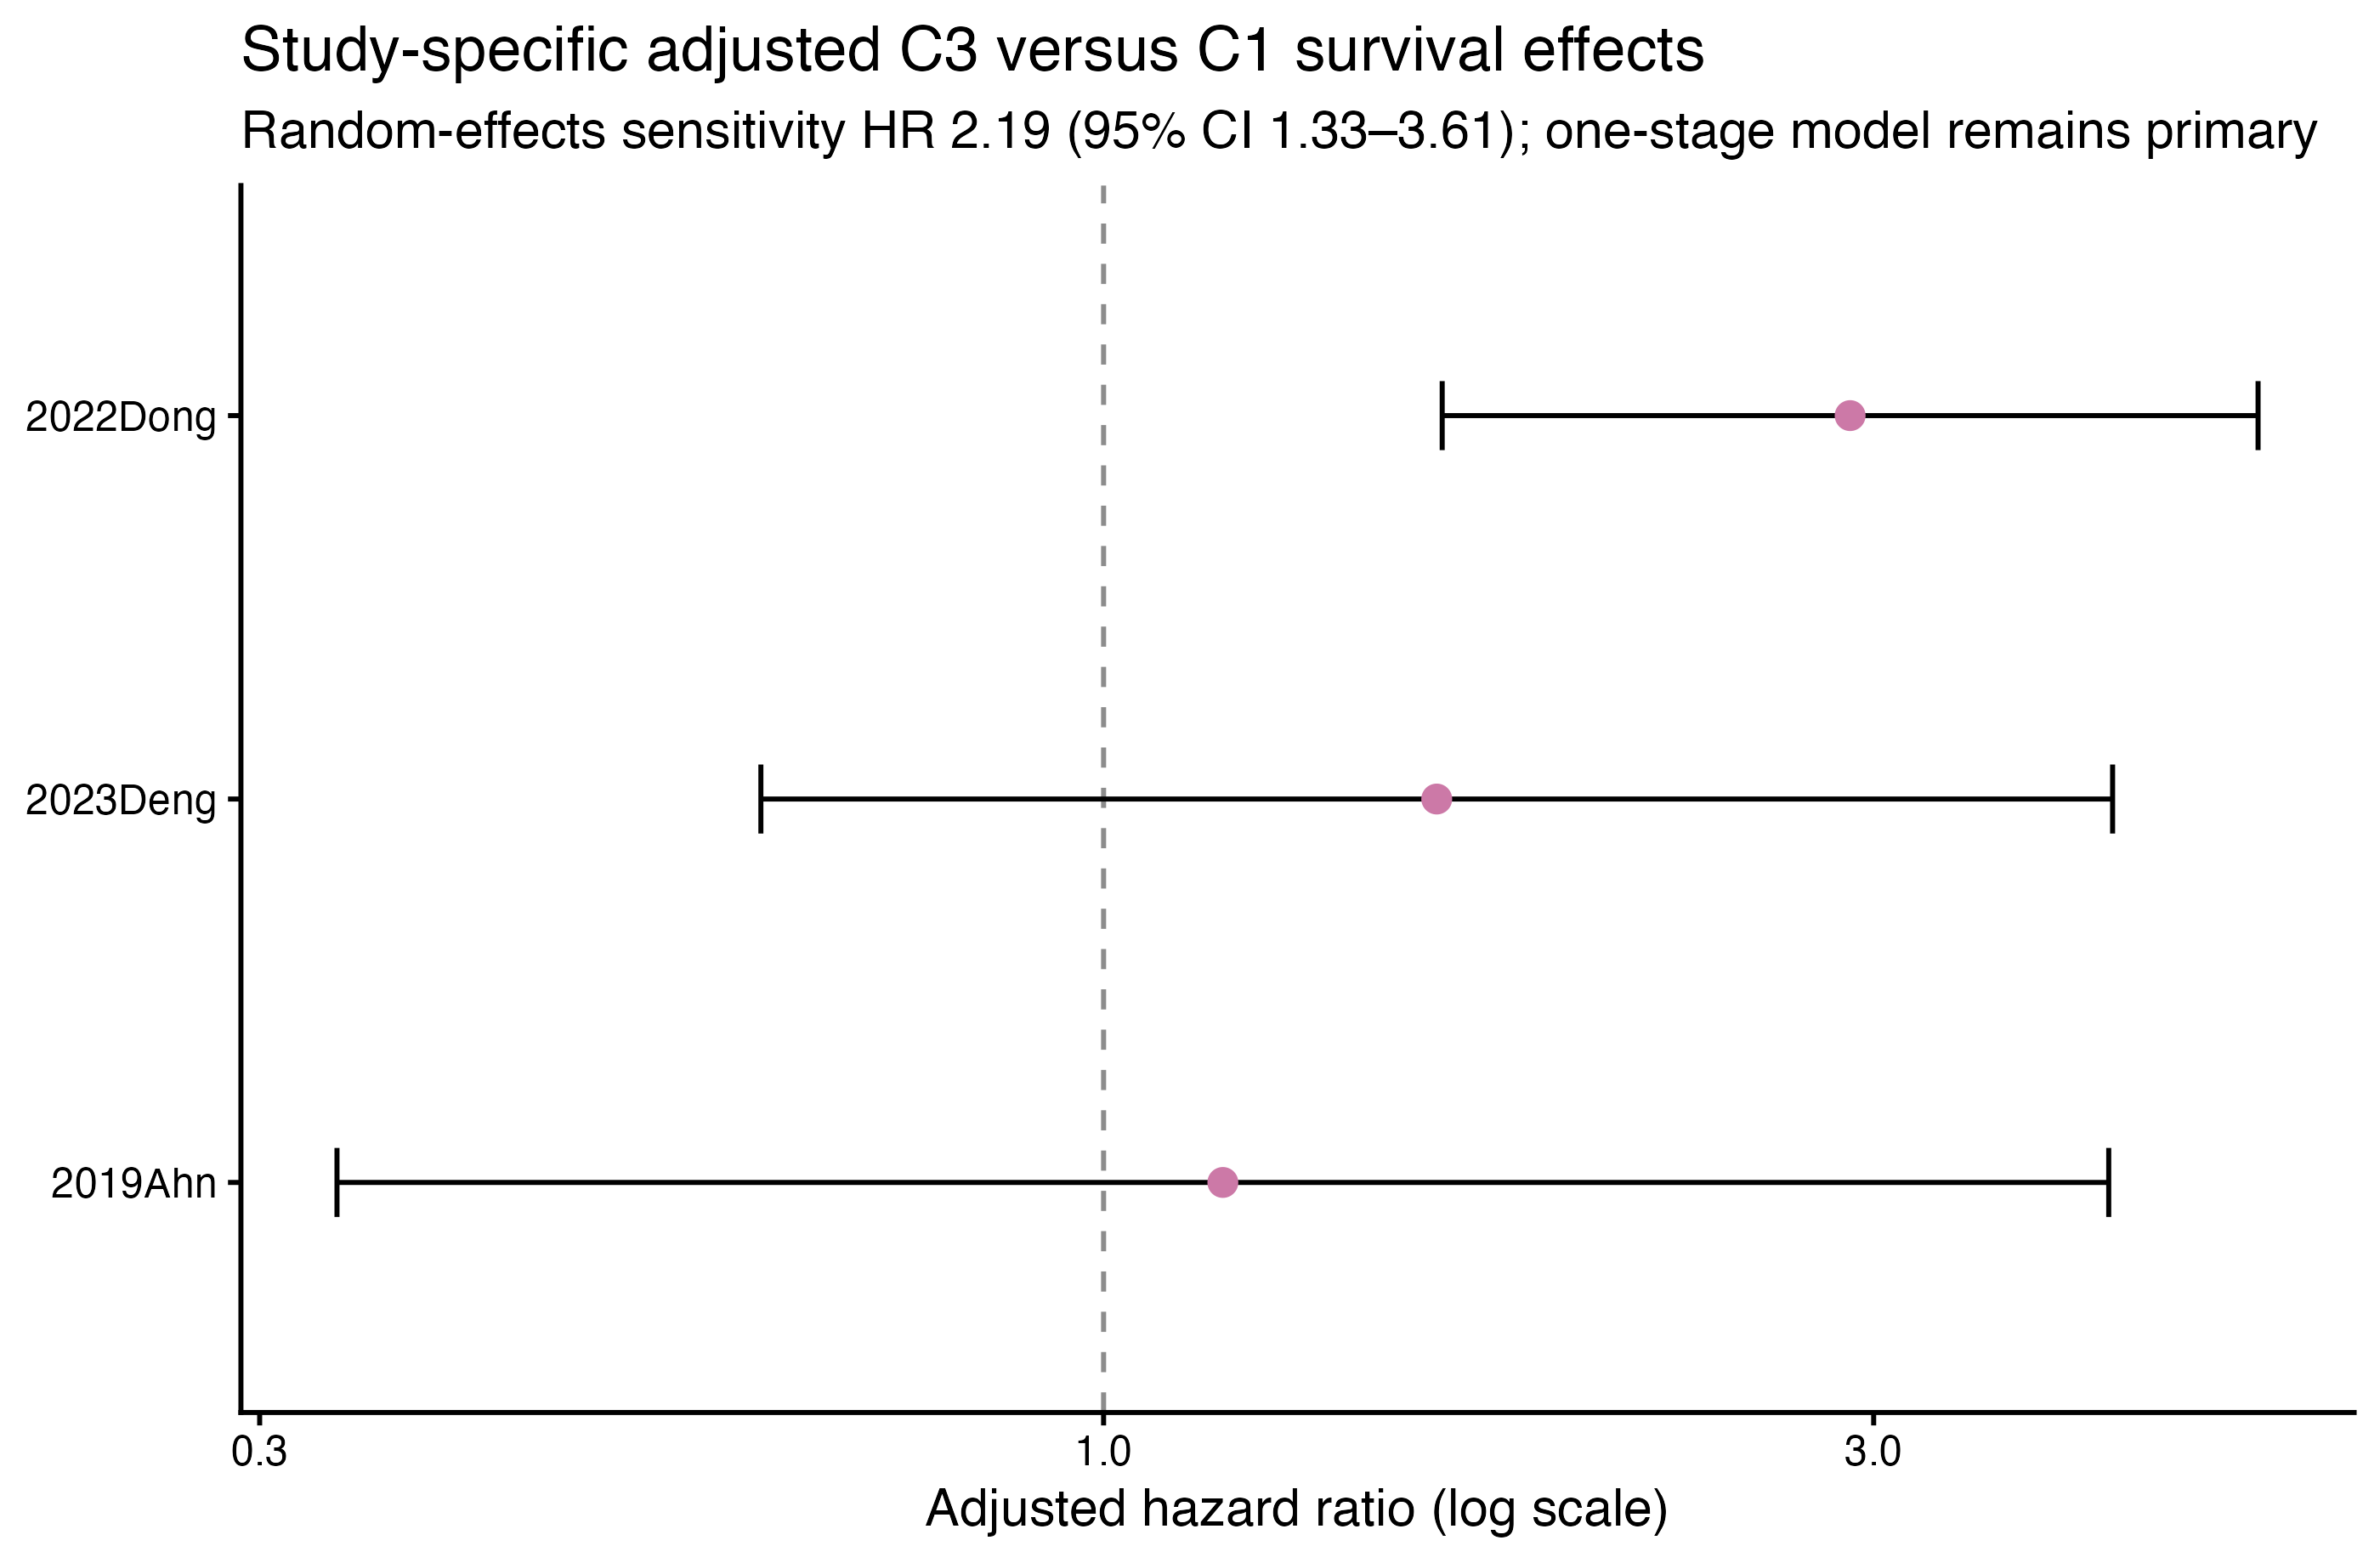

In [5]:
phenotype <- fread(file.path(table_dir, "step6_study_adjusted_clinical_phenotype_contrasts.csv"))
phenotype_meta <- fread(file.path(table_dir, "step6_clinical_phenotype_random_effects_meta.csv"))
incremental <- fread(file.path(table_dir, "step6_incremental_prognostic_performance.csv"))
calibration <- fread(file.path(table_dir, "step6_incremental_prognostic_calibration.csv"))
likelihood_ratio <- fread(file.path(table_dir, "step6_incremental_prognostic_likelihood_ratio.csv"))
cox_meta <- fread(file.path(table_dir, "step6_subtype_cox_random_effects_meta.csv"))
cox_loso <- fread(file.path(table_dir, "step6_subtype_cox_meta_leave_one_study_out.csv"))

phenotype
phenotype_meta
incremental[Comparison == "Delta: clinical + subtype minus clinical"]
calibration[HorizonMonths %in% c(6, 12, 24)]
likelihood_ratio
cox_meta
cox_loso[Target == "C3" & Reference == "C1"]

if (requireNamespace("IRdisplay", quietly = TRUE)) {
  IRdisplay::display_png(file = "6-ClinicalSurvival/publication/figures/step6_incremental_prognostic_value.png")
  IRdisplay::display_png(file = "6-ClinicalSurvival/publication/figures/step6_subtype_cox_meta_forest.png")
}

## Takeaways

C3 is associated with substantially poorer early survival, but the excess hazard declines during follow-up; a constant lifetime hazard-ratio claim is therefore inappropriate. Adding subtype to age, sex and stage improves out-of-fold discrimination and 12/24-month prediction, whereas the 6-month Brier difference and sparse early calibration remain inconclusive. Study-specific meta-analysis supports the adverse C3 direction but becomes imprecise when the dominant 2022Dong cohort is omitted.

Study-adjusted clinical associations place C3 closer to advanced stage, vascular invasion relative to C2, and observed large-duct morphology, but the duct analysis has only 93 patients and substantial study heterogeneity. These associations support clinical relevance without defining C3 by pathology alone.